# kNN ABCD state decoding, trial by trial (item 37)

Loads and plots only. Numbers come from `run_knn_state_decoding.py` under
`sbatch_files/knn_state_decoding.sbatch <lec|pfc>`; write-up `code/KNN_STATE_DECODING.md`.
Samples: one per (trial, state), the mean over leg bins 15-75 of `Neurons_norm`, trial 0
dropped, z-scored per task. Variants: raw, detrend (spline in trial time), centred (minus the
trial's 4-state mean), project (detrend plus removal of the drift subspace). Chance 0.25.

In [1]:
RUN_MODE = 'load'   # never computes; rerun the sbatch jobs instead
import os, pickle
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import knn_state_decoding as kn
import run_knn_state_decoding as rk
%matplotlib inline
# the runner imports run_lda_reward_progress, which switches the backend to Agg
P = {}
for reg, key in (('LEC', 'lec'), ('PFC', 'pfc')):
    with open(rk.OUT_DEFAULT[key], 'rb') as fh:
        P[reg] = pickle.load(fh)
FIG = os.path.join(os.path.dirname(rk.OUT_DEFAULT['lec']), 'figures')
os.makedirs(FIG, exist_ok=True)

## Primaries (mouse means, one-sample t, Holm over four)

In [2]:
pd.concat({reg: p['primaries'][['contrast', 'variant', 'n_mice', 'mean', 'ci', 't', 'p', 'p_holm',
                                 'n_pos', 'per_mouse']] for reg, p in P.items()})

contrast  variant  n_mice      mean  \
LEC 0  W2_near-rand      raw       5  0.002675   
    1  W2_near-rand  centred       5 -0.013071   
    2     X0-chance      raw       5 -0.003988   
    3  X1_near-rand      raw       5 -0.014423   
PFC 0  W2_near-rand      raw       7  0.002824   
    1  W2_near-rand  centred       7 -0.004441   
    2     X0-chance      raw       7 -0.002294   
    3  X1_near-rand      raw       7  0.005429   

                                                   ci         t         p  \
LEC 0   (-0.007873002392832569, 0.013223335788869056)  0.704146  0.520175   
    1    (-0.033642049159457024, 0.00750099981753621) -1.764069  0.152491   
    2   (-0.023425901909136834, 0.015449445629347672) -0.569672  0.599369   
    3    (-0.061543295503960344, 0.03269727206067559) -0.849840  0.443289   
PFC 0   (-0.020373939322159584, 0.026021631432365855)  0.297860  0.775854   
    1    (-0.02986242118616018, 0.020980084349130925) -0.427483  0.683944   
    2   (-0.013502952792553605, 0.008915205475801869) -0.500746  0.634385   
    3  (-7.064829377940486e-05, 0.010928056538258105)  2.415477  0.052183   

         p_holm  n_pos                                          per_mouse  
LEC 0  1.000000      4  {'ah08': 0.0017, 'ah10': -0.0095, 'ly05': 0.00...  
    1  0.609964      1  {'ah08': -0.0222, 'ah10': -0.0362, 'ly05': -0....  
    2  1.000000      2  {'ah08': -0.0211, 'ah10': -0.0003, 'ly05': 0.0...  
    3  1.000000      3  {'ah08': -0.0068, 'ah10': 0.0064, 'ly05': -0.0...  
PFC 0  1.000000      4  {'ab03': -0.0225, 'ah03': 0.01, 'ah04': -0.007...  
    1  1.000000      3  {'ab03': -0.0177, 'ah03': 0.0176, 'ah04': -0.0...  
    2  1.000000      3  {'ab03': -0.0031, 'ah03': 0.0012, 'ah04': 0.01...  
    3  0.208733      6  {'ab03': 0.0001, 'ah03': 0.0031, 'ah04': 0.005...

## Summary figure: W0 / X0 by variant, W2 pools, lag curve, X1 pools

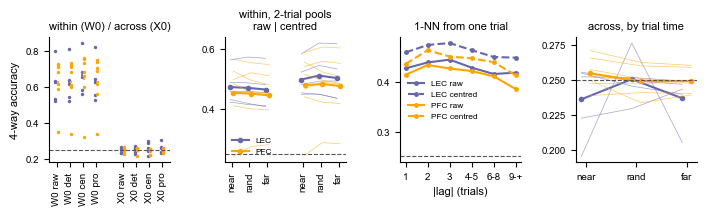

In [3]:
kn.plot_knn_summary(P, out_path=os.path.join(FIG, 'knn_state_summary.svg')); plt.show()

## Place split (X0 raw) and neighbour time-locality

In [4]:
rows = []
for reg, p in P.items():
    x3 = p['x3']
    for col in ('leg_match', 'dest_match'):
        rows.append({'region': reg, 'flag': col, 'shared': x3[x3[col]].correct.mean(),
                     'n_shared': int(x3[col].sum()), 'not': x3[~x3[col]].correct.mean()})
display(pd.DataFrame(rows))
pd.concat({reg: p['diag'].groupby('variant')[['L', 'source_entropy']].mean() for reg, p in P.items()})

,region,flag,shared,n_shared,not
0,LEC,leg_match,0.350548,639,0.242354
1,LEC,dest_match,0.267098,4021,0.237350
2,PFC,leg_match,0.288799,741,0.249516
3,PFC,dest_match,0.262010,4996,0.246082


L  source_entropy
    variant                          
LEC centred -0.006827        0.619365
    detrend -0.004609        0.613661
    project -0.010510        0.596766
    raw      0.245578        0.600581
PFC centred  0.018611        0.614786
    detrend  0.027182        0.605384
    project  0.011278        0.574485
    raw      0.126864        0.589658

## Per-recday X0 raw against its own role null (descriptive; mice are the unit)

In [5]:
pd.concat({reg: p['recday_p'] for reg, p in P.items()})

acc  null_mean         p
LEC ah08_20250613_20250615  0.193056   0.252888  0.844156
    ah08_20250616_20250617  0.225485   0.251507  0.732268
    ah08_20250618_20250619  0.161136   0.251509  0.973027
    ah08_20250620_20250623  0.335971   0.247650  0.011988
    ah10_20250613_20250615  0.240126   0.251615  0.591409
    ah10_20250616_20250617  0.295287   0.251478  0.147852
    ah10_20250618_20250619  0.169680   0.249393  0.978022
    ah10_20250620_20250623  0.217162   0.250126  0.815185
    ah10_20250624_20250625  0.326310   0.248581  0.018981
    ly05_20250613_20250615  0.307777   0.249881  0.055944
    ly05_20250616_20250617  0.172073   0.250075  0.971029
    ly05_20250624_20250625  0.285590   0.250225  0.211788
    ly06_20250613_20250615  0.244904   0.249739  0.577423
    ly06_20250616_20250617  0.298351   0.250064  0.097902
    ly06_20250618_20250619  0.278001   0.250740  0.154845
    ly06_20250620_20250623  0.246956   0.250993  0.535465
    ly06_20250624_20250625  0.257771   0.249276  0.363636
    ly07_20250613_20250615  0.233662   0.249637  0.661339
    ly07_20250616_20250617  0.215871   0.250746  0.804196
    ly07_20250618_20250619  0.186604   0.251121  0.993007
    ly07_20250620_20250623  0.235584   0.247532  0.610390
    ly07_20250624_20250625  0.283729   0.251064  0.198801
PFC ab03_01092023_02092023  0.242556   0.249466  0.567433
    ab03_05092023_06092023  0.201258   0.249942  0.912088
    ab03_29082023_30082023  0.296903   0.250782  0.123876
    ah03_12082021_13082021  0.276024   0.250229  0.127872
    ah03_18082021_19082021  0.226396   0.251049  0.869131
    ah04_01122021_02122021  0.276307   0.251028  0.187812
    ah04_05122021_06122021  0.253108   0.249707  0.440559
    ah04_07122021_08122021  0.254785   0.249597  0.391608
    ah04_09122021_10122021  0.221006   0.248736  0.874126
    ah04_14122021_16122021  0.322186   0.250482  0.013986
    ah07_01092023_02092023  0.217785   0.250348  0.786214
    ah07_27082023_28082023  0.214760   0.249752  0.860140
    ah07_29082023_30082023  0.249075   0.250214  0.529471
    me08_06092021_09092021  0.207785   0.248890  0.915085
    me08_10092021_11092021  0.297157   0.250461  0.097902
    me08_12092021_13092021  0.232594   0.250668  0.670330
    me10_09122021_10122021  0.217572   0.249662  0.965035
    me10_14122021_15122021  0.263778   0.248909  0.289710
    me11_01122021_02122021  0.228394   0.249343  0.744256
    me11_05122021_06122021  0.281365   0.248431  0.191808
    me11_07122021_08122021  0.227723   0.248391  0.725275
    me11_09122021_10122021  0.250481   0.250627  0.503497
    me11_12122021_13122021  0.295142   0.250103  0.083916

## Printed summaries

In [6]:
for reg, key in (('LEC', 'lec'), ('PFC', 'pfc')):
    print(open(rk.OUT_DEFAULT[key].replace('.pkl', '_summary.txt')).read())

== LEC: 24 recdays, 5 mice; skipped 1
-- primaries (mouse means, one-sample t, Holm over four)
  W2_near-rand   raw      mean +0.0027 [-0.0079, +0.0132] t +0.70 p 0.5202 p_holm 1.0000 +4/5  {'ah08': 0.0017, 'ah10': -0.0095, 'ly05': 0.0079, 'ly06': 0.0129, 'ly07': 0.0004}
  W2_near-rand   centred  mean -0.0131 [-0.0336, +0.0075] t -1.76 p 0.1525 p_holm 0.6100 +1/5  {'ah08': -0.0222, 'ah10': -0.0362, 'ly05': -0.0006, 'ly06': 0.0048, 'ly07': -0.0111}
  X0-chance      raw      mean -0.0040 [-0.0234, +0.0154] t -0.57 p 0.5994 p_holm 1.0000 +2/5  {'ah08': -0.0211, 'ah10': -0.0003, 'ly05': 0.0051, 'ly06': 0.0152, 'ly07': -0.0189}
  X1_near-rand   raw      mean -0.0144 [-0.0615, +0.0327] t -0.85 p 0.4433 p_holm 1.0000 +3/5  {'ah08': -0.0068, 'ah10': 0.0064, 'ly05': -0.0814, 'ly06': 0.0004, 'ly07': 0.0093}
-- accuracy, mouse means (recday -> mouse; chance 0.25)
  W0/all/centred             mean 0.666  ah08 0.685 ah10 0.845 ly05 0.582 ly06 0.560 ly07 0.657
  W0/all/detrend             mean 0.627